In [1]:
import numpy as np
import matplotlib.pyplot as plt
from astropy import constants as c
from scipy.signal import welch
from astropy.io import fits
from astropy.wcs import WCS
from scipy import constants as const


### Load the data

In [2]:
# load the data
fp = '/data2/hoppener/radio-astronomy-by-notebooks/test_data/'
file_a1 = 'init_data_1' #antenna 1
file_a2 = 'init_data_2' #antenna 2

# load as np.array
data_a1 = np.fromfile(fp + file_a1, dtype=np.complex64) #antenna 1
data_a2 = np.fromfile(fp + file_a2, dtype=np.complex64) #antenna 2
data_a1 = data_a1[0:len(data_a2)] # data must be same size

In [3]:
print(len(data_a2))

161352318


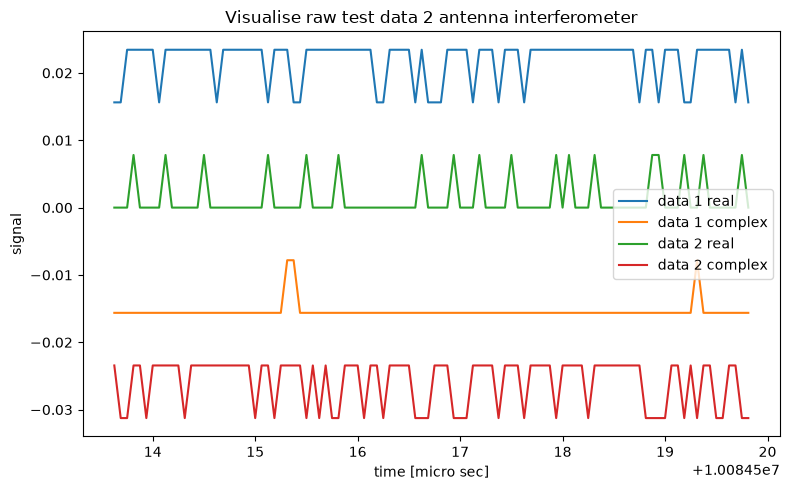

In [4]:
# GNUradio constants
samp_rate = 16e6
center_frequency = 1e8
dt = 1/samp_rate

# calculate the timesteps of the data points
t = np.arange(0, len(data_a2)*dt, dt)

# visualise cut out of raw data
fig, ax = plt.subplots(figsize=(8, 5))
ax.set_title('Visualise raw test data 2 antenna interferometer')
ax.plot(t[len(data_a1)-100:len(data_a1)]*1e6, np.real(data_a1[len(data_a1)-100:len(data_a1)]), label = 'data 1 real')
ax.plot(t[len(data_a1)-100:len(data_a1)]*1e6, np.imag(data_a1[len(data_a1)-100:len(data_a1)]), label = 'data 1 complex')
ax.plot(t[len(data_a2)-100:len(data_a2)]*1e6, np.real(data_a2[len(data_a2)-100:len(data_a2)]), label = 'data 2 real')
ax.plot(t[len(data_a2)-100:len(data_a2)]*1e6, np.imag(data_a2[len(data_a2)-100:len(data_a2)]), label = 'data 2 complex')
ax.set_xlabel("time [micro sec]")
ax.set_ylabel('signal')
ax.legend()
fig.tight_layout()
plt.show()

### Calculate the frequency dependent signal
using the Welch method from; https://www.geeksforgeeks.org/artificial-intelligence/spectrum-analysis-in-python/

In [7]:
# Remove offset
data_a1 = data_a1 - np.mean(data_a1)
data_a2 = data_a2 - np.mean(data_a2)

# Calculate power spectral density using the welch method
freq, psd_a1 = welch(data_a1, fs=samp_rate, nperseg=2**14)

freq, psd_a2 = welch(data_a2, fs=samp_rate, nperseg=2**14)

# Shift central frequency to the center
freq = np.fft.fftshift(freq)
psd_a1 = np.fft.fftshift(psd_a1)
psd_a2 = np.fft.fftshift(psd_a2)

# Convert to absolute RF frequency
freq_rf = center_frequency + freq

# Convert PSD to dB
psd_a1_db = 10 * np.log10(psd_a1)
psd_a2_db = 10 * np.log10(psd_a2)


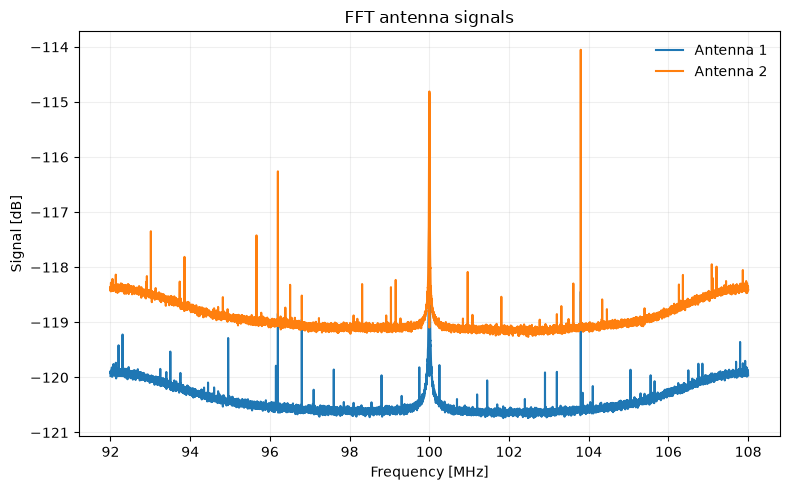

In [8]:
# Plot
fig, ax = plt.subplots(figsize=(8, 5))
ax.set_title('FFT antenna signals')
ax.plot(freq_rf / 1e6, psd_a1_db, label='Antenna 1')
ax.plot(freq_rf / 1e6, psd_a2_db, label='Antenna 2')
ax.set_xlabel('Frequency [MHz]')
ax.set_ylabel('Signal [dB]')
ax.grid(alpha=0.2)
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

### Cross-correlate data


Maximum correlation: 0.9620114920438173
Time delay: 0.0 seconds
Sample shift: 50


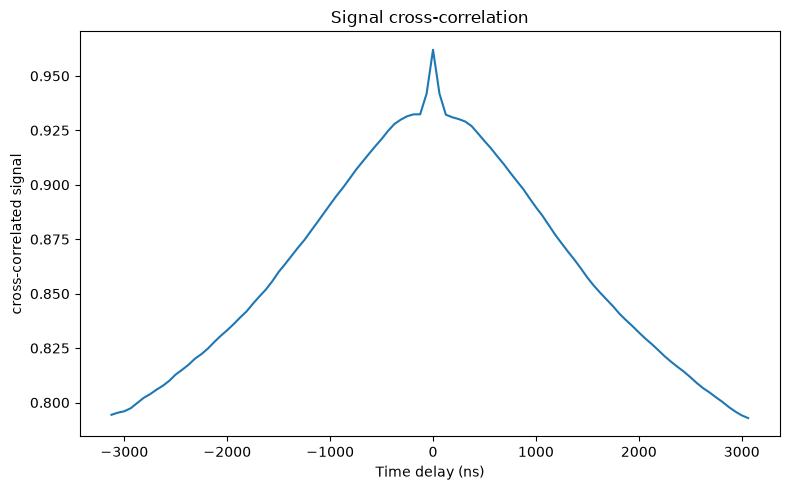

In [12]:
# autocorrelate the signal
n_shifts = 100

correlations = np.zeros(n_shifts)
time_delays = np.zeros(n_shifts)

for i in range(n_shifts):

    # Shift antenna 2 by i samples
    shifted_a2 = np.roll(psd_a2_db, i-50)

    # Calculate Pearson correlation
    correlations[i] = np.corrcoef(psd_a1_db, shifted_a2)[0, 1]

    # Convert sample shift to time delay
    time_delays[i] = i * dt - (50*dt)

# Find maximum correlation
max_index = np.argmax(np.abs(correlations))

print('Maximum correlation:', correlations[max_index])
print('Time delay:', time_delays[max_index], 'seconds')
print('Sample shift:', max_index)

# visualise data
fig, ax = plt.subplots(figsize=(8, 5))
ax.set_title('Signal cross-correlation')
ax.plot(time_delays * 1e9, correlations)
ax.set_xlabel('Time delay (ns)')
ax.set_ylabel('cross-correlated signal')
fig.tight_layout()
plt.show()

### Simulate antenna configuration
from notebook, update later with real configuration

(9, 2)


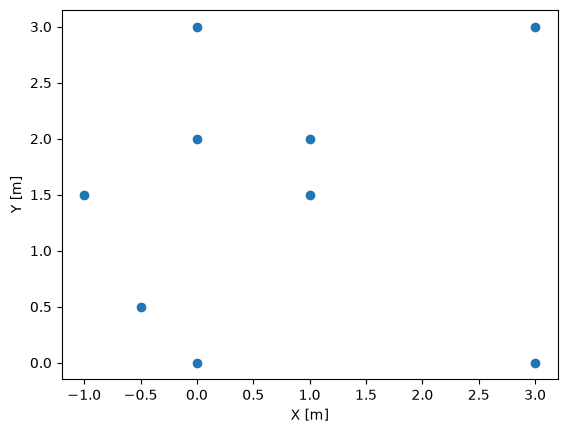

In [19]:
# test some random configuration
list = [[[-0.5],[0.5]],[[0],[0]],[[1],[2]],[[3],[0]],[[-1],[1.5]],[[1],[1.5]],[[0],[2]],[[0],[3]],[[3],[3]]]
ant_pos = np.array(list).reshape((9,2))
print(np.shape(ant_pos))

plt.figure()
plt.scatter(ant_pos[:,0], ant_pos[:,1]) 
plt.xlabel('X [m]')
plt.ylabel('Y [m]')
plt.show()

In [21]:
def compute_uv_coordinates(ant_pos, dtype=np.float32):
    r'''
    Return an array of all uv-coordinates. The array has a shape of
    (num_ant, num_ant, 2), and should be of type `dtype`, and unit 
    `astropy.units.m`
    '''
    num_ant = len(ant_pos)
    u_ant = ant_pos[:,0]   # FILL_IN
    v_ant = ant_pos[:,1]   # FILL_IN
    result = np.zeros((num_ant, num_ant, 2), dtype=dtype)
    for ant1 in range(num_ant):
        for ant2 in range(num_ant):
            result[ant1, ant2] = ant_pos[ant2,:2] - ant_pos[ant1,:2]  #FILL_IN (alternative implementation)
    return result

uv = compute_uv_coordinates(ant_pos)

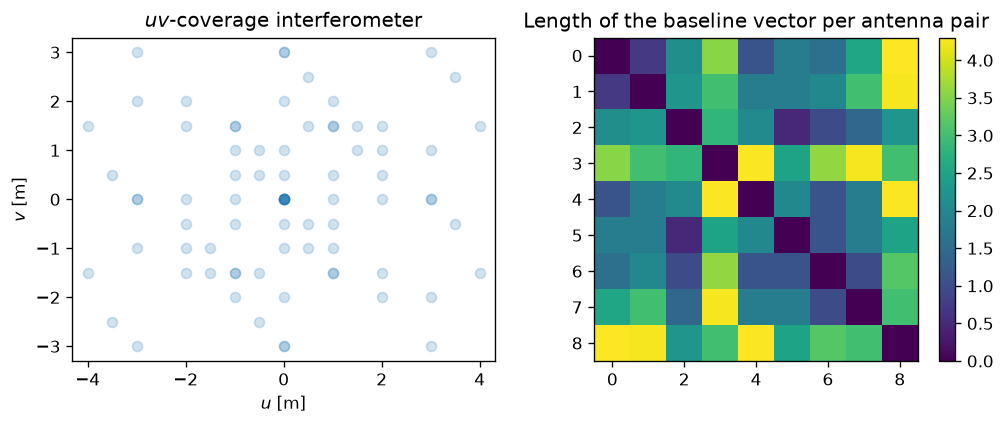

In [22]:
def hdfig(subplots_def=None, scale=0.5, figsize=(8, 4.5)):
    fig = plt.figure(figsize=figsize, dpi=scale*1920/8)
    if subplots_def is None:
        return fig
    else:
        return fig, fig.subplots(*subplots_def) 

fig, (ax_cov, ax_mat) = hdfig((1,2),figsize=(10,3.5))
uv_reshaped = uv.reshape((-1, 2))
ax_cov.set_title('$uv$-coverage interferometer')
ax_cov.set_xlabel('$u$ [m]')
ax_cov.set_ylabel('$v$ [m]')
ax_cov.scatter(uv_reshaped[:,0], uv_reshaped[:,1], alpha=0.2)
ax_cov.axis('equal')

ax_mat.set_title('Length of the baseline vector per antenna pair')
mp_mat = ax_mat.imshow(np.linalg.norm(uv, axis=2))
cb = fig.colorbar(mp_mat)
        

### Make simulated image

In [32]:
over_sampling = 2.5
projection = 20 # rad change later
sub_band = np.where(freq_rf==1e8)[0]
frequency = freq_rf[sub_band]
max_dist = 0
for ant1 in range(len(uv)):
    for ant2 in range(len(uv)):
        uu = uv[ant1, ant2, 0]
        vv = uv[ant1, ant2, 1]
        d = np.sqrt(uu**2+vv**2)
        if d>=max_dist:
            max_dist = d

pixel_separation = (((const.c/(frequency)*(max_dist)))/over_sampling) #rad
num_pix = projection/pixel_separation
print(max_dist, num_pix, pixel_separation)

4.3011627 [3.87760377] [5.15782458]


In [33]:
# pick uneven oversamples number of pixels
num_pix = 13 

In [39]:
from tqdm.notebook import tqdm  # progress bar!

def pixel_brightness_lightning(value, l, m, uv, frequency):

    # Convert baselines from metres to wavelengths.
    uv_lambda = uv * (frequency / const.c)

    # Exclude autocorrelations.
    n = value.shape[0]
    mask = np.ones((n, n), dtype=bool)
    np.fill_diagonal(mask, False)

    # Fourier inversion.
    phase = np.exp(2j * np.pi * (uv_lambda[..., 0] * l + uv_lambda[..., 1] * m))

    brightness = np.sum(np.real(value[mask] * phase[mask]))

    return brightness / np.count_nonzero(mask)


def make_image(acm, num_pix, uv, frequency, l_range=(-1.0, 1.0), m_range=(-1.0, 1.0)):

    img = np.zeros((num_pix, num_pix), dtype=np.float64)

    l_coor = np.linspace(*l_range, num_pix)
    m_coor = np.linspace(*m_range, num_pix)

    for m_ix, m in enumerate(m_coor):
        for l_ix, l in enumerate(l_coor):

            img[m_ix, l_ix] = pixel_brightness_lightning(acm, l, m, uv, frequency)

    # Image extent: left, right, bottom, top.
    dl = abs(l_coor[1] - l_coor[0])
    dm = abs(m_coor[1] - m_coor[0])

    extent = (l_coor[0] - dl/2, l_coor[-1] + dl/2, m_coor[0] - dm/2, m_coor[-1] + dm/2)

    return img, extent


In [ ]:
img_xx, extent = make_image(acm_xx, num_pix, uv, frequency) # FILL_IN
img_yy, _      = make_image(acm_yy, num_pix, uv, frequency) # FILL_IN
img_I = img_xx+img_yy

In [ ]:
fig, ((ax_xx, ax_yy), (ax_i, _)) = hdfig((2,2), figsize=(8,6))
ax_xx.set_title('XX')
mp_xx = ax_xx.imshow(img_xx, origin='lower', extent=extent)
ax_yy.set_title('YY')
mp_yy = ax_yy.imshow(img_yy, origin='lower', extent=extent)
ax_i.set_title('I')
mp_i = ax_i.imshow(img_I, origin='lower', extent=extent)

fig.colorbar(mp_xx, ax=ax_xx)
fig.colorbar(mp_yy, ax=ax_yy)
fig.colorbar(mp_i, ax=ax_i)

img_I.max()
plt.show()